In [43]:
import re
import os
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import gender_guesser.detector as gender


In [44]:
# Load real and fake user data
real_users = pd.read_csv("Dataset/users.csv")
fake_users = pd.read_csv("Dataset/fusers.csv")

# Add labels
real_users["label"] = 1  # Genuine
fake_users["label"] = 0  # Fake/Spam

# 🔁 Merge synthetic fake usernames (if not already merged)
synthetic_fakes = pd.read_csv("Dataset/synthetic_fake_accounts_full.csv")

# Combine and remove duplicates by username
fake_users = pd.concat([fake_users, synthetic_fakes], ignore_index=True).drop_duplicates(subset=["name"])

# Save updated fake dataset (optional)
fake_users.to_csv("Dataset/fusers.csv", index=False)
print(f"✅ Merged fake dataset size: {len(fake_users)}")

# Combine real + fake data
df = pd.concat([real_users, fake_users], ignore_index=True)

print("✅ Dataset loaded successfully!")
print(f"Total records: {len(df)}")
print(f"Genuine: {len(real_users)}, Fake: {len(fake_users)}")
df.head()


✅ Merged fake dataset size: 1437
✅ Dataset loaded successfully!
Total records: 2918
Genuine: 1481, Fake: 1437


,id,name,screen_name,statuses_count,followers_count,friends_count,favourites_count,listed_count,created_at,url,...,profile_background_image_url,profile_background_color,profile_link_color,utc_offset,protected,verified,description,updated,dataset,label
0,3610511,Davide Dellacasa,braddd,20370,5470,2385,145,52,Fri Apr 06 10:58:22 +0000 2007,http://braddd.tumblr.com,...,http://a0.twimg.com/profile_background_images/...,BADFCD,FF0000,3600.0,NaN,NaN,Founder of http://www.screenweek.it & http://w...,2015-02-14 10:54:49,E13,1.0
1,5656162,Simone Economo,eKoeS,3131,506,381,9,40,Mon Apr 30 15:08:42 +0000 2007,http://www.lineheight.net/,...,http://a0.twimg.com/images/themes/theme1/bg.png,C0DEED,0084B4,3600.0,NaN,NaN,BSc degree (cum laude) in Computer Engineering...,2015-02-14 10:54:49,E13,1.0
2,5682702,tacone,tacone_,4024,264,87,323,16,Tue May 01 11:53:40 +0000 2007,http://t.co/LKrl1dZE,...,http://a0.twimg.com/profile_background_images/...,1A1B1F,2FC2EF,3600.0,NaN,NaN,Cogito ergo bestemmio.,2015-02-14 10:54:49,E13,1.0
3,6067292,alesaura,alesstar,40586,640,622,1118,32,Tue May 15 16:55:16 +0000 2007,http://alesstar.wordpress.com/,...,http://a0.twimg.com/images/themes/theme4/bg.gif,0099B9,0099B9,3600.0,NaN,NaN,"Se la vita ti dà sarde, scapocciale!",2015-02-14 10:54:49,E13,1.0
4,6015122,Angelo,PerDiletto,2016,62,64,13,0,Sun May 13 19:52:00 +0000 2007,http://www.flickr.com/per_diletto,...,http://a0.twimg.com/images/themes/theme18/bg.gif,ACDED6,038543,3600.0,NaN,NaN,Je me souviens,2015-02-14 10:54:49,E13,1.0


In [45]:
# Initialize gender detector once
g_detector = gender.Detector(case_sensitive=False)

def extract_username_features_fast(usernames):
    """Extract linguistic, structural, and spam keyword features efficiently."""
    if isinstance(usernames, str):
        usernames = [usernames]

    features = {
        'length': [],
        'num_digits': [],
        'num_upper': [],
        'num_underscore': [],
        'num_special': [],
        'num_vowels': [],
        'digit_ratio': [],
        'vowel_ratio': [],
        'gender_code': [],
        'spam_keyword_count': []
    }

    # Spam keyword list
    spam_keywords = [
        'free', 'gift', 'win', 'cash', 'offer', 'promo', 'deal',
        'bot', 'follow', 'airdrop', 'prize', 'claim', 'reward', 'crypto'
    ]

    gender_dict = {
        'female': -2, 'mostly_female': -1, 'unknown': 0,
        'andy': 0, 'mostly_male': 1, 'male': 2
    }

    for name in usernames:
        name = str(name).strip()
        length = len(name)
        num_digits = sum(c.isdigit() for c in name)
        num_upper = sum(c.isupper() for c in name)
        num_underscore = name.count('_')
        num_special = len(re.findall(r"[^a-zA-Z0-9_]", name))
        num_vowels = len(re.findall(r"[aeiouAEIOU]", name))
        digit_ratio = num_digits / length if length > 0 else 0
        vowel_ratio = num_vowels / length if length > 0 else 0

        # Gender estimation
        first_part = re.split(r'[_\W]+', name)[0]
        gender_type = g_detector.get_gender(first_part)
        gender_code = gender_dict.get(gender_type, 0)

        # Count spam keywords
        spam_count = sum(1 for word in spam_keywords if word in name.lower())

        # Append all
        features['length'].append(length)
        features['num_digits'].append(num_digits)
        features['num_upper'].append(num_upper)
        features['num_underscore'].append(num_underscore)
        features['num_special'].append(num_special)
        features['num_vowels'].append(num_vowels)
        features['digit_ratio'].append(digit_ratio)
        features['vowel_ratio'].append(vowel_ratio)
        features['gender_code'].append(gender_code)
        features['spam_keyword_count'].append(spam_count)

    return pd.DataFrame(features)


In [ ]:
print("⏳ Extracting features...")

X = extract_username_features_fast(df["name"])
y = df["label"]

print("✅ Features extracted successfully!")
print("Shape:", X.shape)
X.head()


In [46]:
print("⏳ Extracting features...")

X = extract_username_features_fast(df["name"])
y = df["label"]

print("✅ Features extracted successfully!")
print("Shape:", X.shape)
X.head()


⏳ Extracting features...
✅ Features extracted successfully!
Shape: (2918, 10)


,length,num_digits,num_upper,num_underscore,num_special,num_vowels,digit_ratio,vowel_ratio,gender_code,spam_keyword_count
0,16,0,2,0,1,7,0.0,0.4375,2,0
1,14,0,2,0,1,7,0.0,0.5000,-2,0
2,6,0,0,0,0,3,0.0,0.5000,0,0
3,8,0,0,0,0,5,0.0,0.6250,0,0
4,6,0,1,0,0,3,0.0,0.5000,2,0


In [47]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

print(f"Training samples: {X_train.shape[0]}")
print(f"Testing samples: {X_test.shape[0]}")


Training samples: 2042
Testing samples: 876


In [48]:
clf = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1,
    max_depth=None
)

clf.fit(X_train, y_train)
print("✅ Model training completed!")


✅ Model training completed!


🎯 Model Accuracy: 87.67%

📋 Classification Report:

              precision    recall  f1-score   support

        Fake       0.85      0.90      0.88       429
     Genuine       0.90      0.85      0.88       447

    accuracy                           0.88       876
   macro avg       0.88      0.88      0.88       876
weighted avg       0.88      0.88      0.88       876



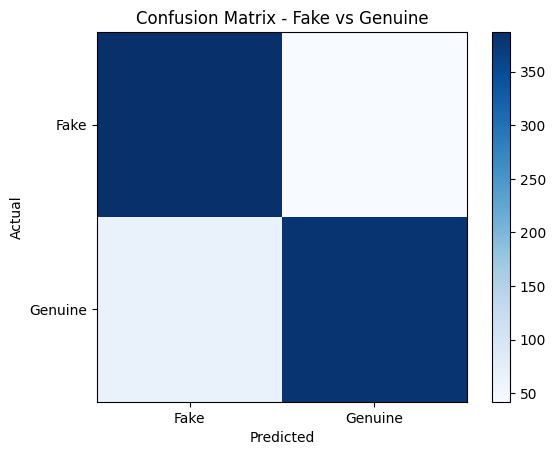

In [49]:
y_pred = clf.predict(X_test)
acc = accuracy_score(y_test, y_pred)

print(f"🎯 Model Accuracy: {acc*100:.2f}%")
print("\n📋 Classification Report:\n")
print(classification_report(y_test, y_pred, target_names=['Fake', 'Genuine']))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.imshow(cm, cmap="Blues")
plt.title("Confusion Matrix - Fake vs Genuine")
plt.colorbar()
plt.xticks([0,1], ['Fake','Genuine'])
plt.yticks([0,1], ['Fake','Genuine'])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


In [50]:
os.makedirs("model", exist_ok=True)

model_data = {
    "model": clf,
    "scaler": None,
    "feature_columns": X.columns.tolist()
}

joblib.dump(model_data, "model/random_forest_model.pkl")
print("✅ Model saved at: model/random_forest_model.pkl")


✅ Model saved at: model/random_forest_model.pkl


In [52]:
# Load model
model_data = joblib.load("model/random_forest_model.pkl")
model = model_data["model"]

def predict_username(username):
    # Extract features for the given username
    features = extract_username_features_fast([username])  # wrap in list for correct shape

    # Ensure correct feature column order
    model_features = model_data["feature_columns"]
    features = features.reindex(columns=model_features, fill_value=0)

    # Predict class and probability
    pred = model.predict(features)[0]
    proba = model.predict_proba(features)[0][int(pred)]

    # Return label and confidence
    return ("✅ Genuine Account", proba) if pred == 1 else ("⚠️ Fake/Spam Account", proba)


# Test examples
test_usernames = [
    "xXx_freegift99_xXx",
    "crypto_airdrop_bot",
    "!!claimreward2025!!",
    "win_money_2025",
    "john_doe123",
    "anna_smith",
    "real_person"
]

print("🔍 Test Predictions:\n")
for name in test_usernames:
    label, conf = predict_username(name)
    print(f"{name:25s} → {label} (Confidence: {conf*100:.2f}%)")


🔍 Test Predictions:

xXx_freegift99_xXx        → ⚠️ Fake/Spam Account (Confidence: 80.50%)
crypto_airdrop_bot        → ⚠️ Fake/Spam Account (Confidence: 91.50%)
!!claimreward2025!!       → ⚠️ Fake/Spam Account (Confidence: 68.00%)
win_money_2025            → ✅ Genuine Account (Confidence: 50.50%)
john_doe123               → ✅ Genuine Account (Confidence: 85.83%)
anna_smith                → ✅ Genuine Account (Confidence: 91.83%)
real_person               → ✅ Genuine Account (Confidence: 92.50%)
